<a href="https://colab.research.google.com/github/Sgnsilv/ResearchAtlas/blob/6-machine-learning-implementar-baseline-tf-idf-k-means/notebooks/02_clusterizacao.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ResearchAtlas — Clusterização Semântica

**Issue #06 — Experimentos de clusterização**

## Objetivo

Investigar agrupamentos semânticos de artigos científicos sobre aplicações de Inteligência Artificial em cinco áreas do conhecimento.

## Dados

- Dataset: ResearchAtlas v1
- Artigos: 5.000
- Representação: BGE-small-en-v1.5
- Dimensões: 384
- Vetores normalizados: L2

## Metodologia inicial

1. Carregamento e validação dos embeddings.
2. Implementação do K-Means.
3. Experimentação de diferentes quantidades de clusters.
4. Avaliação dos agrupamentos.
5. Comparação com outros algoritmos.
6. Exportação dos resultados.

As áreas científicas serão utilizadas para **interpretação e avaliação posterior**, não como rótulos de treinamento.


In [1]:
%pip install -q numpy pandas pyarrow scikit-learn matplotlib

import hashlib
import json
import random
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

print("=== AMBIENTE ===")
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Semente:", SEED)


=== AMBIENTE ===
NumPy: 2.4.6
Pandas: 2.2.3
Scikit-learn: 1.6.1
Semente: 42


In [2]:
PROJECT_DIR = Path("/content/ResearchAtlas")

if not PROJECT_DIR.exists():
    subprocess.run(
        [
            "git", "clone",
            "--branch", "dev",
            "--single-branch",
            "https://github.com/Sgnsilv/ResearchAtlas.git",
            str(PROJECT_DIR),
        ],
        check=True,
    )

print("=== REPOSITÓRIO ===")
print("Diretório:", PROJECT_DIR)
print("Existe:", PROJECT_DIR.exists())


=== REPOSITÓRIO ===
Diretório: /content/ResearchAtlas
Existe: True


In [3]:
ARTIFACT_DIR = (
    PROJECT_DIR
    / "data/processed/embeddings/bge-small-en-v1.5-v1"
)

EMBEDDINGS_PATH = ARTIFACT_DIR / "embeddings.npy"
METADATA_PATH = ARTIFACT_DIR / "metadata.parquet"
MANIFEST_PATH = ARTIFACT_DIR / "manifest.json"

EXPECTED_HASH = (
    "13fe24f37622790f6d6630fbdb5e91742060f95a8d7310597d3bd98f2a7f465c"
)

with EMBEDDINGS_PATH.open("rb") as file:
    actual_hash = hashlib.file_digest(
        file, "sha256"
    ).hexdigest()

assert actual_hash == EXPECTED_HASH, (
    "Os embeddings não correspondem à versão de referência."
)

embeddings = np.load(
    EMBEDDINGS_PATH,
    allow_pickle=False,
)

metadata = pd.read_parquet(METADATA_PATH)

manifest = json.loads(
    MANIFEST_PATH.read_text(encoding="utf-8")
)

print("=== ARTEFATOS CARREGADOS ===")
print("Embeddings:", embeddings.shape)
print("Metadados:", metadata.shape)
print("Modelo:", manifest["model"])
print("SHA-256: APROVADO")


=== ARTEFATOS CARREGADOS ===
Embeddings: (5000, 384)
Metadados: (5000, 9)
Modelo: BAAI/bge-small-en-v1.5
SHA-256: APROVADO


In [4]:
assert embeddings.shape == (5000, 384)
assert embeddings.dtype == np.float32
assert np.isfinite(embeddings).all()

assert len(metadata) == 5000
assert metadata["openalex_id"].is_unique
assert metadata["embedding_index"].tolist() == list(range(5000))

norms = np.linalg.norm(
    embeddings,
    axis=1,
)

assert np.allclose(norms, 1.0, atol=1e-5)

print("=== INTEGRIDADE ===")
print("Artigos:", len(metadata))
print("Dimensões:", embeddings.shape[1])
print("IDs únicos:", metadata["openalex_id"].nunique())
print("Norma mínima:", norms.min())
print("Norma máxima:", norms.max())

print("\n=== ARTIGOS POR ÁREA ===")
print(metadata["sampling_area"].value_counts())

print("\nVALIDAÇÃO: APROVADA")


=== INTEGRIDADE ===
Artigos: 5000
Dimensões: 384
IDs únicos: 5000
Norma mínima: 0.99999994
Norma máxima: 1.0

=== ARTIGOS POR ÁREA ===
sampling_area
Medicina      1000
Astronomia    1000
Biologia      1000
Clima         1000
Engenharia    1000
Name: count, dtype: int64

VALIDAÇÃO: APROVADA


In [5]:
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
)

K = 5

kmeans = KMeans(
    n_clusters=K,
    random_state=SEED,
    n_init=10,
)

labels = kmeans.fit_predict(embeddings)

# Silhouette amostral para manter a avaliação rápida.
silhouette = silhouette_score(
    embeddings,
    labels,
    metric="cosine",
    sample_size=2000,
    random_state=SEED,
)

# DB e CH usam a geometria euclidiana do espaço original.
davies_bouldin = davies_bouldin_score(
    embeddings,
    labels,
)

calinski_harabasz = calinski_harabasz_score(
    embeddings,
    labels,
)

print("=== EXPERIMENTO INICIAL — K-MEANS ===")
print("Número de clusters:", K)
print("Silhouette (cosseno):", round(silhouette, 4))
print("Davies-Bouldin:", round(davies_bouldin, 4))
print("Calinski-Harabasz:", round(calinski_harabasz, 2))

print("\n=== TAMANHO DOS CLUSTERS ===")
print(
    pd.Series(labels, name="cluster")
    .value_counts()
    .sort_index()
    .to_string()
)


=== EXPERIMENTO INICIAL — K-MEANS ===
Número de clusters: 5
Silhouette (cosseno): 0.136
Davies-Bouldin: 3.2154
Calinski-Harabasz: 255.21

=== TAMANHO DOS CLUSTERS ===
cluster
0     882
1    1132
2    1004
3    1044
4     938


In [6]:
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
)
from tqdm.auto import tqdm

K_VALUES = range(2, 16)
SILHOUETTE_SAMPLE = 2000

results = []

for k in tqdm(K_VALUES, desc="Avaliando K-Means"):
    model = KMeans(
        n_clusters=k,
        random_state=SEED,
        n_init=10,
    )

    cluster_labels = model.fit_predict(embeddings)

    silhouette = silhouette_score(
        embeddings,
        cluster_labels,
        metric="cosine",
        sample_size=SILHOUETTE_SAMPLE,
        random_state=SEED,
    )

    db = davies_bouldin_score(
        embeddings,
        cluster_labels,
    )

    ch = calinski_harabasz_score(
        embeddings,
        cluster_labels,
    )

    cluster_sizes = np.bincount(
        cluster_labels,
        minlength=k,
    )

    results.append({
        "k": k,
        "silhouette": silhouette,
        "davies_bouldin": db,
        "calinski_harabasz": ch,
        "inertia": model.inertia_,
        "min_cluster_size": int(cluster_sizes.min()),
        "max_cluster_size": int(cluster_sizes.max()),
    })

results_df = pd.DataFrame(results)

print("=== COMPARAÇÃO DE K-MEANS ===")
display(results_df.round(4))


Avaliando K-Means:   0%|          | 0/14 [00:00<?, ?it/s]

=== COMPARAÇÃO DE K-MEANS ===


,k,silhouette,davies_bouldin,calinski_harabasz,inertia,min_cluster_size,max_cluster_size
0,2,0.1282,3.5909,361.865204,1694.7246,1932,3068
1,3,0.1244,3.4107,304.154205,1620.1898,1060,2031
2,4,0.1363,3.1697,277.581696,1557.7750,954,1909
3,5,0.1360,3.2154,255.206696,1509.0267,882,1132
4,6,0.1378,3.0721,229.983994,1477.2690,426,1058
5,7,0.1424,3.0094,210.305206,1450.7844,359,987
6,8,0.1472,3.2192,192.446899,1431.2074,352,993
7,9,0.1189,2.9904,175.684097,1418.0906,145,967
8,10,0.1200,3.5210,164.584396,1401.4241,325,722
9,11,0.1299,3.3082,154.734604,1387.1877,142,857


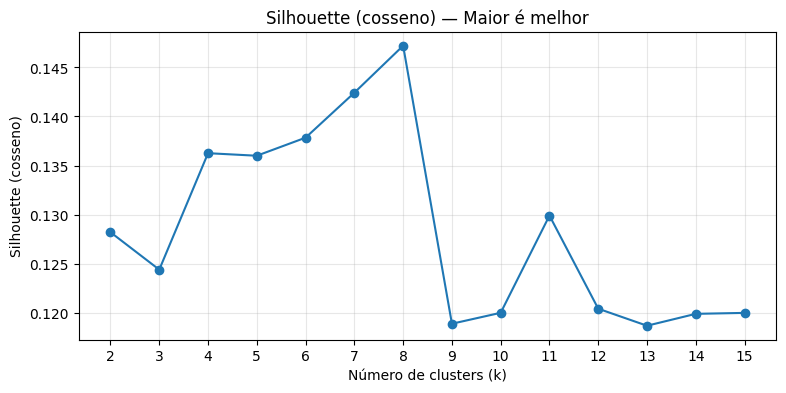

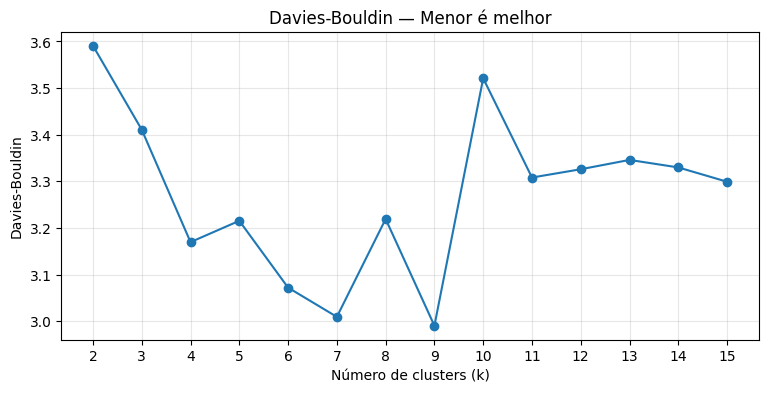

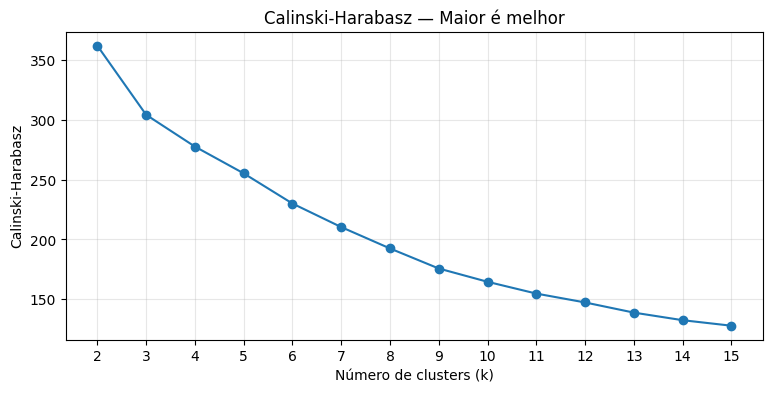

In [7]:
import matplotlib.pyplot as plt

metrics = [
    ("silhouette", "Silhouette (cosseno)", "Maior é melhor"),
    ("davies_bouldin", "Davies-Bouldin", "Menor é melhor"),
    ("calinski_harabasz", "Calinski-Harabasz", "Maior é melhor"),
]

for column, title, direction in metrics:
    plt.figure(figsize=(9, 4))

    plt.plot(
        results_df["k"],
        results_df[column],
        marker="o",
    )

    plt.title(f"{title} — {direction}")
    plt.xlabel("Número de clusters (k)")
    plt.ylabel(title)
    plt.xticks(list(K_VALUES))
    plt.grid(alpha=0.3)
    plt.show()


In [8]:
best_silhouette = results_df.loc[
    results_df["silhouette"].idxmax()
]

best_db = results_df.loc[
    results_df["davies_bouldin"].idxmin()
]

best_ch = results_df.loc[
    results_df["calinski_harabasz"].idxmax()
]

print("=== MELHORES CONFIGURAÇÕES ===")

print(
    f"Silhouette: k={int(best_silhouette['k'])} "
    f"(score={best_silhouette['silhouette']:.4f})"
)

print(
    f"Davies-Bouldin: k={int(best_db['k'])} "
    f"(score={best_db['davies_bouldin']:.4f})"
)

print(
    f"Calinski-Harabasz: k={int(best_ch['k'])} "
    f"(score={best_ch['calinski_harabasz']:.2f})"
)

print("\nObservação: não escolher k apenas por uma métrica.")


=== MELHORES CONFIGURAÇÕES ===
Silhouette: k=8 (score=0.1472)
Davies-Bouldin: k=9 (score=2.9904)
Calinski-Harabasz: k=2 (score=361.87)

Observação: não escolher k apenas por uma métrica.


In [9]:
from itertools import combinations

from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from tqdm.auto import tqdm

CANDIDATE_K = [5, 7, 8, 9]
STABILITY_SEEDS = [11, 21, 42, 73, 101]

stability_results = []
stability_labels = {}

for k in tqdm(CANDIDATE_K, desc="Avaliando estabilidade"):
    runs = {}

    for seed in STABILITY_SEEDS:
        model = KMeans(
            n_clusters=k,
            random_state=seed,
            n_init=10,
        )
        runs[seed] = model.fit_predict(embeddings)

    stability_labels[k] = runs

    scores = [
        adjusted_rand_score(runs[a], runs[b])
        for a, b in combinations(STABILITY_SEEDS, 2)
    ]

    stability_results.append({
        "k": k,
        "ari_mean": float(np.mean(scores)),
        "ari_std": float(np.std(scores)),
        "ari_min": float(np.min(scores)),
        "ari_max": float(np.max(scores)),
    })

stability_df = pd.DataFrame(stability_results)

print("=== ESTABILIDADE DO K-MEANS ===")
display(stability_df.round(4))


Avaliando estabilidade:   0%|          | 0/4 [00:00<?, ?it/s]

=== ESTABILIDADE DO K-MEANS ===


,k,ari_mean,ari_std,ari_min,ari_max
0,5,0.9979,0.0012,0.9956,1.0000
1,7,0.9471,0.0594,0.8735,1.0000
2,8,0.8621,0.0915,0.7518,0.9928
3,9,0.8926,0.0628,0.8236,0.9961



=== COMPOSIÇÃO DOS CLUSTERS — k=7 ===


sampling_area,Astronomia,Biologia,Clima,Engenharia,Medicina
cluster,,,,,
0,37,51,22,65,252
1,30,6,27,892,5
2,2,602,3,1,53
3,875,0,10,1,0
4,0,33,3,3,681
5,41,4,932,9,1
6,15,304,3,29,8



Proporções por cluster:


sampling_area,Astronomia,Biologia,Clima,Engenharia,Medicina
cluster,,,,,
0,0.087,0.119,0.052,0.152,0.590
1,0.031,0.006,0.028,0.929,0.005
2,0.003,0.911,0.005,0.002,0.080
3,0.988,0.000,0.011,0.001,0.000
4,0.000,0.046,0.004,0.004,0.946
5,0.042,0.004,0.944,0.009,0.001
6,0.042,0.847,0.008,0.081,0.022


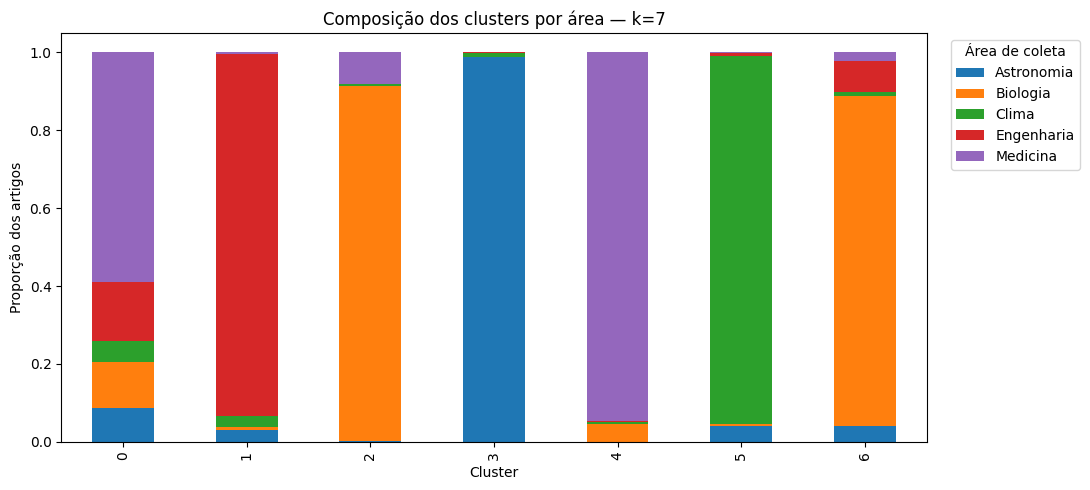


=== COMPOSIÇÃO DOS CLUSTERS — k=8 ===


sampling_area,Astronomia,Biologia,Clima,Engenharia,Medicina
cluster,,,,,
0,9,4,11,492,6
1,13,304,3,25,7
2,877,0,10,1,1
3,23,4,16,429,1
4,4,595,3,1,51
5,44,4,935,9,1
6,0,34,3,3,678
7,30,55,19,40,255



Proporções por cluster:


sampling_area,Astronomia,Biologia,Clima,Engenharia,Medicina
cluster,,,,,
0,0.017,0.008,0.021,0.943,0.011
1,0.037,0.864,0.009,0.071,0.020
2,0.987,0.000,0.011,0.001,0.001
3,0.049,0.008,0.034,0.907,0.002
4,0.006,0.910,0.005,0.002,0.078
5,0.044,0.004,0.942,0.009,0.001
6,0.000,0.047,0.004,0.004,0.944
7,0.075,0.138,0.048,0.100,0.639


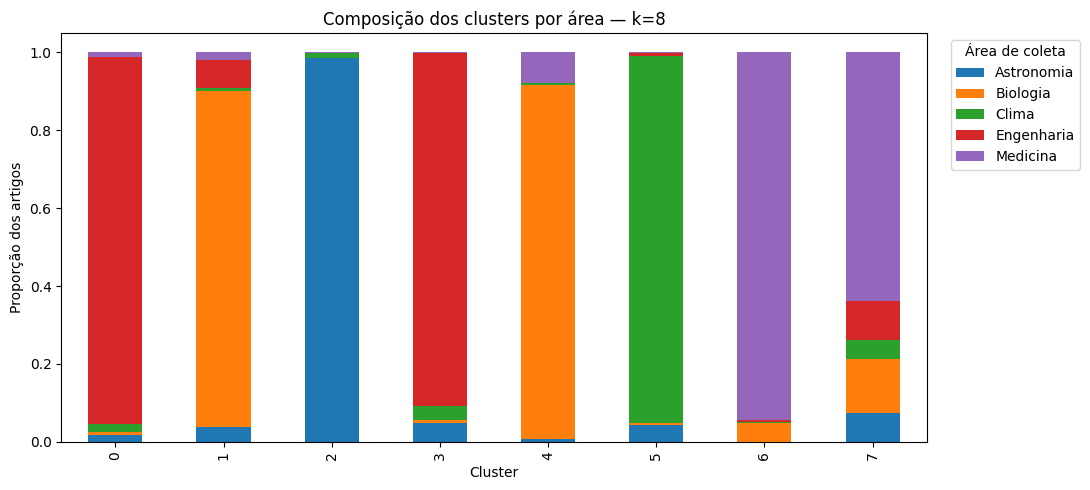

In [10]:
import matplotlib.pyplot as plt

for k in [7, 8]:
    labels_k = stability_labels[k][42]

    composition = pd.crosstab(
        pd.Series(labels_k, name="cluster"),
        metadata["sampling_area"].reset_index(drop=True),
    )

    proportions = composition.div(
        composition.sum(axis=1),
        axis=0,
    )

    print(f"\n=== COMPOSIÇÃO DOS CLUSTERS — k={k} ===")
    display(composition)

    print("\nProporções por cluster:")
    display(proportions.round(3))

    ax = proportions.plot(
        kind="bar",
        stacked=True,
        figsize=(11, 5),
    )

    ax.set_title(f"Composição dos clusters por área — k={k}")
    ax.set_xlabel("Cluster")
    ax.set_ylabel("Proporção dos artigos")
    ax.legend(
        title="Área de coleta",
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
    )

    plt.tight_layout()
    plt.show()


In [11]:
from sklearn.cluster import KMeans
from sklearn.metrics.pairwise import cosine_similarity

REPRESENTATIVE_K = [7, 8]
TOP_ARTICLES = 5

cluster_models = {}
cluster_labels = {}

for k in REPRESENTATIVE_K:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10,
    )

    labels = model.fit_predict(embeddings)

    cluster_models[k] = model
    cluster_labels[k] = labels

    # Similaridade de cada artigo com o centro do seu cluster.
    similarities = cosine_similarity(
        embeddings,
        model.cluster_centers_,
    )

    print(f"\n{'=' * 60}")
    print(f"ARTIGOS REPRESENTATIVOS — K={k}")
    print("=" * 60)

    for cluster_id in range(k):
        indices = np.where(labels == cluster_id)[0]

        ranked_indices = sorted(
            indices,
            key=lambda idx: similarities[idx, cluster_id],
            reverse=True,
        )

        top_indices = ranked_indices[:TOP_ARTICLES]

        print(f"\n--- CLUSTER {cluster_id} ---")
        print(f"Total de artigos: {len(indices)}")

        for rank, idx in enumerate(top_indices, start=1):
            article = metadata.iloc[idx]

            print(
                f"{rank}. [{article['sampling_area']}] "
                f"{article['title']}"
            )

print("\nINTERPRETAÇÃO INICIAL: ARTIGOS IDENTIFICADOS")



ARTIGOS REPRESENTATIVOS — K=7

--- CLUSTER 0 ---
Total de artigos: 427
1. [Medicina] Advancements, Applications, and Future Directions of Artificial Intelligence in Healthcare
2. [Medicina] Transforming Medicine: A Comprehensive Review of Artificial Intelligence in Healthcare
3. [Medicina] Artificial Intelligence and Machine Learning in Precision Medicine: Applications, Challenges, and Ethical Perspectives
4. [Medicina] Future of the Artificial Intelligence in Daily Health Applications
5. [Medicina] Artificial Intelligence in Healthcare: Transforming Diagnosis, Treatment, and Patient Care

--- CLUSTER 1 ---
Total de artigos: 960
1. [Engenharia] Machine learning and deep learning based methods toward industry 4.0 predictive maintenance in induction motors: State of the art survey
2. [Engenharia] Fault Identification Model Using Convolutional Neural Networks with Transformer Architecture
3. [Engenharia] AI-driven embedded systems for predictive maintenance in industrial IoT
4. [Engenhar

In [12]:
from sklearn.metrics.pairwise import cosine_similarity

K = 8
CLUSTER_ID = 7
TOP_PER_AREA = 5

model = cluster_models[K]
labels = cluster_labels[K]

cluster_indices = np.where(labels == CLUSTER_ID)[0]

centroid = model.cluster_centers_[CLUSTER_ID].reshape(1, -1)

similarities = cosine_similarity(
    embeddings[cluster_indices],
    centroid,
).ravel()

cluster_df = metadata.iloc[cluster_indices].copy()

cluster_df["similarity_to_centroid"] = similarities
cluster_df["cluster"] = CLUSTER_ID

print("=== ANÁLISE INTERDISCIPLINAR — K=8, CLUSTER 7 ===")
print("Total de artigos:", len(cluster_df))

for area in sorted(cluster_df["sampling_area"].unique()):
    subset = (
        cluster_df[
            cluster_df["sampling_area"] == area
        ]
        .sort_values(
            "similarity_to_centroid",
            ascending=False,
        )
        .head(TOP_PER_AREA)
    )

    print(f"\n{'=' * 65}")
    print(f"ÁREA: {area.upper()}")
    print(f"Total na área: {(cluster_df['sampling_area'] == area).sum()}")
    print("=" * 65)

    for _, article in subset.iterrows():
        print(
            f"\nSimilaridade: "
            f"{article['similarity_to_centroid']:.4f}"
        )
        print(f"Título: {article['title']}")
        print(f"OpenAlex: {article['openalex_id']}")


=== ANÁLISE INTERDISCIPLINAR — K=8, CLUSTER 7 ===
Total de artigos: 399

ÁREA: ASTRONOMIA
Total na área: 30

Similaridade: 0.8600
Título: Artificial Intelligence As a Driver of Modern Science: from Biomedicine to International Megascience Projects
OpenAlex: https://openalex.org/W7133239991

Similaridade: 0.8324
Título: On the “Life-Likeness” of Synthetic Cells
OpenAlex: https://openalex.org/W3081421405

Similaridade: 0.8300
Título: From Archaea and Cyanobacteria to Algoid: Life and Living Matter in the Context of Evolutionary Theory
OpenAlex: https://openalex.org/W4408489003

Similaridade: 0.8212
Título: Biological research and self-driving labs in deep space supported by artificial intelligence
OpenAlex: https://openalex.org/W4360612437

Similaridade: 0.8066
Título: Is artificial intelligence the great filter that makes advanced technical civilisations rare in the universe?
OpenAlex: https://openalex.org/W4393930779

ÁREA: BIOLOGIA
Total na área: 55

Similaridade: 0.8898
Título: Cardi

In [13]:
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.metrics.pairwise import cosine_similarity

dataset_path = (
    PROJECT_DIR / "data/processed/dataset_selected.parquet"
)

articles = pd.read_parquet(dataset_path)

# Confirma correspondência entre artigos e embeddings.
assert articles["openalex_id"].tolist() == (
    metadata["openalex_id"].tolist()
)

K = 8
CLUSTER_ID = 7
TOP_PER_AREA = 5

model = cluster_models[K]
labels = cluster_labels[K]

indices = np.where(labels == CLUSTER_ID)[0]

centroid = model.cluster_centers_[CLUSTER_ID].reshape(1, -1)

similarities = cosine_similarity(
    embeddings[indices],
    centroid,
).ravel()

audit_df = articles.iloc[indices][
    [
        "openalex_id",
        "title",
        "abstract",
        "sampling_area",
        "publication_year",
        "quality_flags",
    ]
].copy()

audit_df["similarity_to_centroid"] = similarities

# Seleciona cinco artigos representativos por área.
audit_sample = (
    audit_df
    .sort_values("similarity_to_centroid", ascending=False)
    .groupby("sampling_area", sort=True)
    .head(TOP_PER_AREA)
    .sort_values(
        ["sampling_area", "similarity_to_centroid"],
        ascending=[True, False],
    )
    .reset_index(drop=True)
)

# Campos para revisão humana.
audit_sample["connection_type"] = ""
audit_sample["scientific_relevance"] = ""
audit_sample["justification"] = ""

output_path = Path("/content/cluster_7_auditoria.csv")

audit_sample.to_csv(
    output_path,
    index=False,
    encoding="utf-8-sig",
)

print("=== AUDITORIA TEMÁTICA ===")
print("Cluster:", CLUSTER_ID)
print("Artigos selecionados:", len(audit_sample))
print("Arquivo:", output_path)

display(
    audit_sample[
        [
            "sampling_area",
            "title",
            "similarity_to_centroid",
            "quality_flags",
        ]
    ]
)

assert len(audit_sample) == 25

print("\nAMOSTRA DE AUDITORIA: APROVADA")


=== AUDITORIA TEMÁTICA ===
Cluster: 7
Artigos selecionados: 25
Arquivo: /content/cluster_7_auditoria.csv


,sampling_area,title,similarity_to_centroid,quality_flags
0,Astronomia,Artificial Intelligence As a Driver of Modern ...,0.860001,[]
1,Astronomia,On the “Life-Likeness” of Synthetic Cells,0.832368,"[""long_abstract""]"
2,Astronomia,From Archaea and Cyanobacteria to Algoid: Life...,0.830009,[]
3,Astronomia,Biological research and self-driving labs in d...,0.821236,[]
4,Astronomia,Is artificial intelligence the great filter th...,0.806581,[]
5,Biologia,Cardiologists 2018: Personalized and translati...,0.889768,"[""long_abstract""]"
6,Biologia,Artificial intelligence in food and nutrition ...,0.887846,[]
7,Biologia,POTENTIAL APPLICATIONTS OF ARTIFICIAL INTELLIG...,0.886555,[]
8,Biologia,Artificial intelligence applications in nutrit...,0.885808,[]
9,Biologia,Artificial Intelligence in Nutritional Plannin...,0.884225,[]



AMOSTRA DE AUDITORIA: APROVADA


In [14]:
from pathlib import Path
from google.colab import drive
import shutil

drive.mount("/content/drive")

AUDIT_DIR = Path(
    "/content/drive/MyDrive/ResearchAtlas/audits/cluster_7_k8"
)

AUDIT_DIR.mkdir(parents=True, exist_ok=True)

source = Path("/content/cluster_7_auditoria.csv")

for reviewer in ("reviewer_1", "reviewer_2"):
    destination = AUDIT_DIR / f"{reviewer}.csv"
    shutil.copy2(source, destination)
    print("Salvo:", destination)

print("\nARQUIVOS DE AUDITORIA: PREPARADOS")


Mounted at /content/drive
Salvo: /content/drive/MyDrive/ResearchAtlas/audits/cluster_7_k8/reviewer_1.csv
Salvo: /content/drive/MyDrive/ResearchAtlas/audits/cluster_7_k8/reviewer_2.csv

ARQUIVOS DE AUDITORIA: PREPARADOS
